# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import numpy as np
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from IPython.display import display

REPO = os.environ.get("BIGDATA_REPO", "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate")
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,codigo_departamento,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,longitud_territorial,latitud_territorial,estado_union_inicial,estado_union,fuente_analisis,fuente_territorial
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,52,52835,NARIÑO,SAN ANDRÉS DE TUMACO,-78.764073,1.807399,coincide,coincide,agrosavia.csv,divipola.csv (2024)
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,41,41676,HUILA,SANTA MARÍA,-75.586223,2.939603,coincide,coincide,agrosavia.csv,divipola.csv (2024)
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,05,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,coincide,agrosavia.csv,divipola.csv (2024)
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,05,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,coincide,agrosavia.csv,divipola.csv (2024)
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,05,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,coincide,agrosavia.csv,divipola.csv (2024)


(92738, 49)
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable                         object
Magnesio intercambiable           

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 49)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ Secuencia ┆ Fecha de  ┆ Departame ┆ Municipio ┆ … ┆ estado_un ┆ estado_un ┆ fuente_an ┆ fuente_t │
│ l         ┆ Análisis  ┆ nto       ┆ ---       ┆   ┆ ion_inici ┆ ion       ┆ alisis    ┆ erritori │
│ ---       ┆ ---       ┆ ---       ┆ str       ┆   ┆ al        ┆ ---       ┆ ---       ┆ al       │
│ str       ┆ str       ┆ str       ┆           ┆   ┆ ---       ┆ str       ┆ str       ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆ str       ┆           ┆           ┆ str      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1         ┆ 7/01/2014 ┆ NARIÑO    ┆ SAN       ┆ … ┆ coincide  ┆ coincide  ┆ agrosavia ┆ divipola │
│           ┆           ┆           ┆ ANDRÉS DE ┆   ┆           ┆           ┆ .csv      ┆ .csv     │
│           ┆           ┆           ┆ TUMACO    ┆   ┆           ┆           

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [4]:
# 1. Contrato común y consulta
COLS = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]
TIPOS_PD = {"id_fila": "Int64", "anio": "Int64", "codigo_departamento": "string",
            "codigo_municipio": "string", "ph": "Float64", "ph_valido": "boolean"}
TIPOS_PL = {"id_fila": pl.Int64, "anio": pl.Int64, "codigo_departamento": pl.Utf8,
            "codigo_municipio": pl.Utf8, "ph": pl.Float64, "ph_valido": pl.Boolean}
# En CSV: nulo = celda vacía; códigos se leen como texto para conservar ceros iniciales.

proyeccion_pd = datos_pd[COLS].astype(TIPOS_PD).sort_values("id_fila").reset_index(drop=True)
proyeccion_pl = datos_pl.select([pl.col(c).cast(t) for c, t in TIPOS_PL.items()]).sort("id_fila")
N = len(proyeccion_pd)
assert N == proyeccion_pl.height == len(datos_pd)
print("Filas:", N, "| nulos por columna:", proyeccion_pd.isna().sum().to_dict())

DEPARTAMENTO = "15"  # Boyacá, igual que el mapa de PD04
if not proyeccion_pd["codigo_departamento"].eq(DEPARTAMENTO).any():
    DEPARTAMENTO = proyeccion_pd["codigo_departamento"].value_counts().index[0]
ANIO = int(proyeccion_pd.loc[proyeccion_pd["codigo_departamento"].eq(DEPARTAMENTO), "anio"].value_counts().idxmax())
print("Consulta: departamento", DEPARTAMENTO, "| año", ANIO)

def consulta_pd(tabla):
    filtro = tabla[tabla["anio"].eq(ANIO).fillna(False) & tabla["codigo_departamento"].eq(DEPARTAMENTO).fillna(False)]
    filtro = filtro.assign(ph_para_media=filtro["ph"].where(filtro["ph_valido"].fillna(False)))
    return (filtro.groupby("codigo_municipio", dropna=False)
            .agg(total_analisis=("id_fila", "size"),
                 ph_validos=("ph_valido", "sum"),
                 media_ph=("ph_para_media", "mean"))
            .reset_index())

def consulta_pl(tabla):
    return (tabla
            .filter((pl.col("anio") == ANIO) & (pl.col("codigo_departamento") == DEPARTAMENTO))
            .group_by("codigo_municipio")                       # Polars conserva la clave nula como grupo
            .agg(pl.len().alias("total_analisis"),
                 pl.col("ph_valido").sum().alias("ph_validos"),
                 pl.col("ph").filter(pl.col("ph_valido")).mean().alias("media_ph")))

def comparar(res_pd, res_pl):
    a = res_pd.sort_values("codigo_municipio", na_position="last").reset_index(drop=True)
    b = res_pl.sort("codigo_municipio", nulls_last=True).to_pandas()
    assert a["codigo_municipio"].isna().tolist() == b["codigo_municipio"].isna().tolist(), "nulos en otra posición"
    assert a["codigo_municipio"].fillna("<NA>").tolist() == b["codigo_municipio"].fillna("<NA>").tolist()
    assert a["total_analisis"].astype(int).tolist() == b["total_analisis"].astype(int).tolist()
    assert a["ph_validos"].astype(int).tolist() == b["ph_validos"].astype(int).tolist()
    ma, mb = a["media_ph"].astype(float).to_numpy(), b["media_ph"].astype(float).to_numpy()
    assert np.array_equal(np.isnan(ma), np.isnan(mb)), "media ausente en otra posición"
    assert np.allclose(ma, mb, atol=1e-6, rtol=0, equal_nan=True)
    return True

resultado_pd = consulta_pd(proyeccion_pd)
resultado_pl = consulta_pl(proyeccion_pl)
print("Equivalentes:", comparar(resultado_pd, resultado_pl),
      "| municipios:", len(resultado_pd), "| grupo sin municipio:", bool(resultado_pd["codigo_municipio"].isna().any()),
      "| medias ausentes:", int(resultado_pd["media_ph"].isna().sum()))
display(resultado_pd.sort_values("total_analisis", ascending=False).head(10))

Filas: 92738 | nulos por columna: {'id_fila': 0, 'anio': 0, 'codigo_departamento': 2040, 'codigo_municipio': 2040, 'ph': 11, 'ph_valido': 0}
Consulta: departamento 15 | año 2015
Equivalentes: True | municipios: 75 | grupo sin municipio: False | medias ausentes: 0


,codigo_municipio,total_analisis,ph_validos,media_ph
51,15686,123,123,5.272187
9,15176,114,114,5.124211
65,15816,98,98,4.938878
7,15131,91,91,5.238857
50,15676,75,75,4.86272
48,15646,67,67,5.166284
39,15516,62,62,4.957113
1,15047,59,59,5.568915
41,15533,57,57,4.974789
3,15087,55,55,5.532527


**Interpretación:**

Las dos proyecciones tienen las mismas 6 columnas, el mismo número de filas y tipos equivalentes (enteros nullable, texto para los códigos, decimal y booleano). La consulta filtra un año y un departamento y agrupa por municipio. En pandas uso `dropna=False`; en Polars, `group_by` ya conserva la clave nula como grupo. Al comparar, revisé claves y conteos exactos, medias con tolerancia de 0,000001, y que los nulos estén en las mismas posiciones, no solo los totales.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [5]:
# 2. Particionamiento manual desde pandas
def nueva_ejecucion(nombre):
    ruta = Path(OUT) / f"{nombre}_{datetime.now():%Y%m%d_%H%M%S_%f}"
    ruta.mkdir(parents=True, exist_ok=False)
    return ruta

def construir_representaciones(EJECUCION, tabla):
    rutas = {"csv": EJECUCION / "unico.csv", "parquet": EJECUCION / "unico.parquet"}
    tabla.to_csv(rutas["csv"], index=False, na_rep="")
    tabla.to_parquet(rutas["parquet"], engine="pyarrow", compression="snappy", index=False)

    # Por año
    carpeta = Path(EJECUCION) / "por_anio"
    carpeta.mkdir(parents=True, exist_ok=False)
    inventario = []
    for numero, (anio, grupo) in enumerate(tabla.groupby("anio", dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        inventario.append({"anio": anio, "archivo": str(archivo.relative_to(EJECUCION)),
                           "filas": len(grupo), "bytes": archivo.stat().st_size})
    pd.DataFrame(inventario).to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)

    # Por año y departamento
    carpeta = Path(EJECUCION) / "por_anio_departamento"
    carpeta.mkdir(parents=True, exist_ok=False)
    inventario = []
    for numero, ((anio, depto), grupo) in enumerate(
            tabla.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        inventario.append({"anio": anio, "codigo_departamento": depto,
                           "archivo": str(archivo.relative_to(EJECUCION)),
                           "filas": len(grupo), "bytes": archivo.stat().st_size})
    pd.DataFrame(inventario).to_csv(Path(EJECUCION) / "inventario_anio_departamento.csv", index=False)
    return rutas

TIPOS_INVENTARIO = {"anio": "Int64", "codigo_departamento": "string", "archivo": "string",
                    "filas": "int64", "bytes": "int64"}

def releer_particiones(EJECUCION, nombre_inventario):
    inventario = pd.read_csv(Path(EJECUCION) / nombre_inventario,
                             dtype={k: v for k, v in TIPOS_INVENTARIO.items()})
    partes = [pd.read_parquet(Path(EJECUCION) / ruta, engine="pyarrow") for ruta in inventario["archivo"]]
    return inventario, pd.concat(partes, ignore_index=True).sort_values("id_fila").reset_index(drop=True)

EJECUCION = nueva_ejecucion("ejecucion_A")
RUTAS = construir_representaciones(EJECUCION, proyeccion_pd)

resumen_diseños = []
for nombre_inv, diseno in [("inventario_anio.csv", "por_anio"),
                           ("inventario_anio_departamento.csv", "por_anio_departamento")]:
    inventario, releida = releer_particiones(EJECUCION, nombre_inv)
    pd.testing.assert_frame_equal(releida, proyeccion_pd)
    assert releida["id_fila"].is_unique and set(releida["id_fila"]) == set(proyeccion_pd["id_fila"])
    resumen_diseños.append({"diseno": diseno, "archivos": len(inventario), "filas": int(inventario["filas"].sum()),
                            "bytes": int(inventario["bytes"].sum()),
                            "mediana_filas_por_archivo": float(inventario["filas"].median()),
                            "archivos_con_menos_de_100_filas": int(inventario["filas"].lt(100).sum())})
    print(diseno, "→ releído idéntico:", len(releida), "filas")
    display(inventario.head())
resumen_diseños += [{"diseno": "csv_unico", "archivos": 1, "filas": N, "bytes": RUTAS["csv"].stat().st_size},
                    {"diseno": "parquet_unico", "archivos": 1, "filas": N, "bytes": RUTAS["parquet"].stat().st_size}]
resumen_diseños = pd.DataFrame(resumen_diseños)
display(resumen_diseños)

por_anio → releído idéntico: 92738 filas


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96641
1,2015,por_anio/parte-0001.parquet,13228,117840
2,2016,por_anio/parte-0002.parquet,14539,130769
3,2017,por_anio/parte-0003.parquet,7655,72422
4,2018,por_anio/parte-0004.parquet,4208,42184


por_anio_departamento → releído idéntico: 92738 filas


,anio,codigo_departamento,archivo,filas,bytes
0,2014,05,por_anio_departamento/parte-0000.parquet,517,8351
1,2014,08,por_anio_departamento/parte-0001.parquet,16,4035
2,2014,11,por_anio_departamento/parte-0002.parquet,24,4056
3,2014,13,por_anio_departamento/parte-0003.parquet,192,5486
4,2014,15,por_anio_departamento/parte-0004.parquet,484,8143


,diseno,archivos,filas,bytes,mediana_filas_por_archivo,archivos_con_menos_de_100_filas
0,por_anio,12,92738,865014,7442.0,0.0
1,por_anio_departamento,373,92738,2256128,109.0,179.0
2,csv_unico,1,92738,2750014,NaN,NaN
3,parquet_unico,1,92738,830598,NaN,NaN


**Interpretación:**

Escribí la misma proyección de cuatro formas: CSV único, Parquet único, partes por año y partes por año y departamento. Cada parte conserva todas sus columnas, incluidas las claves, y el `groupby(dropna=False)` mantiene los grupos con clave ausente. Al releer todas las partes desde el inventario y unirlas, la tabla es idéntica a la original y los `id_fila` son únicos. Por año y departamento se generan muchos archivos pequeños, y cada uno repite su encabezado y sus metadatos; por eso ocupa más bytes que el Parquet único. Dividir en archivos no hace que el procesamiento sea paralelo.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [6]:
# 3. Lectura y escritura comparables (1 ejecución inicial + 5 repeticiones alternando el orden)
REPETICIONES = 5
mediciones = []
VERSION = {"pandas": pd.__version__, "polars": pl.__version__}

def registrar(motor, operacion, formato, particion, repeticion, segundos, filas_in, filas_out):
    mediciones.append({"motor": motor, "version": VERSION[motor], "operacion": operacion, "formato": formato,
                       "particionamiento": particion, "repeticion": repeticion, "inicial": repeticion == 0,
                       "segundos": segundos, "filas_entrada": filas_in, "filas_salida": filas_out})

carpeta_escritura = nueva_ejecucion("escrituras")
for rep in range(REPETICIONES + 1):                       # rep 0 = ejecución inicial
    motores = ["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]
    for motor in motores:
        # --- lectura CSV ---
        if motor == "pandas":
            t0 = time.perf_counter()
            leido = pd.read_csv(RUTAS["csv"], sep=",", dtype=TIPOS_PD, keep_default_na=True)
            t = time.perf_counter() - t0
        else:
            t0 = time.perf_counter()
            leido = pl.read_csv(RUTAS["csv"], separator=",", schema_overrides=TIPOS_PL, null_values=[""])
            t = time.perf_counter() - t0
        registrar(motor, "lectura", "csv", "unico", rep, t, N, len(leido))
        # --- lectura Parquet ---
        if motor == "pandas":
            t0 = time.perf_counter()
            leido = pd.read_parquet(RUTAS["parquet"], engine="pyarrow")
            t = time.perf_counter() - t0
        else:
            t0 = time.perf_counter()
            leido = pl.read_parquet(RUTAS["parquet"])
            t = time.perf_counter() - t0
        registrar(motor, "lectura", "parquet", "unico", rep, t, N, len(leido))
        # --- escritura CSV y Parquet (datos ya en memoria; ruta nueva cada vez) ---
        destino_csv = carpeta_escritura / f"{motor}_{rep}.csv"
        destino_pq = carpeta_escritura / f"{motor}_{rep}.parquet"
        if motor == "pandas":
            t0 = time.perf_counter()
            proyeccion_pd.to_csv(destino_csv, index=False, na_rep="")
            t = time.perf_counter() - t0
            registrar(motor, "escritura", "csv", "unico", rep, t, N, N)
            t0 = time.perf_counter()
            proyeccion_pd.to_parquet(destino_pq, engine="pyarrow", compression="snappy", index=False)
            t = time.perf_counter() - t0
            registrar(motor, "escritura", "parquet", "unico", rep, t, N, N)
        else:
            t0 = time.perf_counter()
            proyeccion_pl.write_csv(destino_csv, null_value="")
            t = time.perf_counter() - t0
            registrar(motor, "escritura", "csv", "unico", rep, t, N, N)
            t0 = time.perf_counter()
            proyeccion_pl.write_parquet(destino_pq, compression="snappy")
            t = time.perf_counter() - t0
            registrar(motor, "escritura", "parquet", "unico", rep, t, N, N)

# Fuera del reloj: lo leído y lo escrito es equivalente al contrato
lect_pd = pd.read_csv(RUTAS["csv"], dtype=TIPOS_PD)
lect_pl = pl.read_csv(RUTAS["csv"], schema_overrides=TIPOS_PL, null_values=[""]).to_pandas()
pd.testing.assert_frame_equal(lect_pd, proyeccion_pd)
assert np.allclose(lect_pl["ph"].astype(float), proyeccion_pd["ph"].astype(float), equal_nan=True)
assert lect_pl["codigo_municipio"].fillna("<NA>").tolist() == proyeccion_pd["codigo_municipio"].fillna("<NA>").tolist()
for motor in ["pandas", "polars"]:
    pd.testing.assert_frame_equal(pd.read_parquet(carpeta_escritura / f"{motor}_1.parquet").astype(TIPOS_PD), proyeccion_pd)
    pd.testing.assert_frame_equal(pd.read_csv(carpeta_escritura / f"{motor}_1.csv", dtype=TIPOS_PD), proyeccion_pd)
print("Lecturas y escrituras equivalentes al contrato")

tabla_med = pd.DataFrame(mediciones)
resumen_es = (tabla_med[~tabla_med["inicial"]]
              .groupby(["operacion", "formato", "motor"])["segundos"]
              .agg(mediana="median", minimo="min", maximo="max").reset_index())
display(resumen_es)
with open("/proc/meminfo") as f:
    memoria = {l.split(":")[0]: l.split(":")[1].strip() for l in f if l.startswith(("MemTotal", "MemAvailable"))}
print("CPU lógicas:", os.cpu_count(), "| RAM:", memoria, "| archivos en:", OUT)

Lecturas y escrituras equivalentes al contrato


,operacion,formato,motor,mediana,minimo,maximo
0,escritura,csv,pandas,0.684734,0.349831,0.751907
1,escritura,csv,polars,0.168632,0.051045,0.212600
2,escritura,parquet,pandas,0.114750,0.097292,0.172991
3,escritura,parquet,polars,0.085477,0.041507,0.088253
4,lectura,csv,pandas,0.143326,0.104356,0.167739
5,lectura,csv,polars,0.063266,0.035020,0.083439
6,lectura,parquet,pandas,0.047131,0.017333,0.053344
7,lectura,parquet,polars,0.058486,0.019438,0.068446


CPU lógicas: 24 | RAM: {'MemTotal': '8129536 kB', 'MemAvailable': '2073212 kB'} | archivos en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05


**Interpretación:**

Medí con `perf_counter` justo antes y después de cada llamada: una ejecución inicial aparte y cinco repeticiones alternando qué motor va primero. Las lecturas CSV incluyen los tipos del contrato (códigos como texto y celdas vacías como nulos); las escrituras parten de los datos ya cargados en memoria y cada una va a un archivo nuevo. Hay una diferencia que no pude igualar: pandas escribe los booleanos como `True`/`False` y Polars como `true`/`false`; al releer los dos se interpretan igual. No controlé la caché del sistema operativo, así que estas lecturas no son "en frío": después de la primera vez el archivo puede quedar en memoria. Los archivos están en `/mnt/c` (disco de Windows visto desde WSL), lo que hace más lenta la entrada y salida.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [7]:
# 4. Procesamiento en memoria y consulta desde disco
COLS_LEER = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]
referencia = consulta_pd(proyeccion_pd)

# --- 4.1 En memoria: solo filtro + agregación ---
for rep in range(REPETICIONES + 1):
    for motor in (["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]):
        if motor == "pandas":
            t0 = time.perf_counter(); res = consulta_pd(proyeccion_pd); t = time.perf_counter() - t0
        else:
            t0 = time.perf_counter(); res = consulta_pl(proyeccion_pl); t = time.perf_counter() - t0
        registrar(motor, "consulta_memoria", "memoria", "ninguno", rep, t, N, len(res))

# --- 4.2 Desde disco ---
def rutas_por_inventario(nombre_inventario, con_departamento):
    inventario = pd.read_csv(EJECUCION / nombre_inventario, dtype=TIPOS_INVENTARIO)
    sel = inventario["anio"].eq(ANIO).fillna(False)
    if con_departamento:
        sel &= inventario["codigo_departamento"].eq(DEPARTAMENTO).fillna(False)
    return [str(EJECUCION / r) for r in inventario.loc[sel, "archivo"]]

VARIANTES = {
    "unico": lambda: [str(RUTAS["parquet"])],
    "por_anio": lambda: rutas_por_inventario("inventario_anio.csv", False),
    "por_anio_departamento": lambda: rutas_por_inventario("inventario_anio_departamento.csv", True),
}
for nombre, selector in VARIANTES.items():
    rutas = selector()
    print(f"{nombre}: {len(rutas)} archivo(s) seleccionados →", [Path(r).name for r in rutas][:5])
    assert rutas, f"La consulta no tiene archivos candidatos en {nombre}"

def desde_disco_pd(selector):
    rutas_seleccionadas = selector()                       # incluye leer el inventario
    partes_pd = []
    for ruta in rutas_seleccionadas:
        parte_pd = pd.read_parquet(ruta, engine="pyarrow", columns=COLS_LEER)
        partes_pd.append(parte_pd)
    seleccion_pd = pd.concat(partes_pd, ignore_index=True)
    return consulta_pd(seleccion_pd)

def desde_disco_pl(selector):
    rutas_seleccionadas = selector()
    partes_pl = []
    for ruta in rutas_seleccionadas:
        parte_pl = pl.read_parquet(ruta, columns=COLS_LEER)
        partes_pl.append(parte_pl)
    seleccion_pl = pl.concat(partes_pl)
    return consulta_pl(seleccion_pl)

def lazy_pl():
    return consulta_pl(pl.scan_parquet(RUTAS["parquet"]).select(COLS_LEER)).collect()

for rep in range(REPETICIONES + 1):
    for nombre, selector in VARIANTES.items():
        for motor in (["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]):
            if motor == "pandas":
                t0 = time.perf_counter(); res = desde_disco_pd(selector); t = time.perf_counter() - t0
                comparar(res, pl.from_pandas(referencia))
            else:
                t0 = time.perf_counter(); res = desde_disco_pl(selector); t = time.perf_counter() - t0
                comparar(referencia, res)
            registrar(motor, "consulta_disco", "parquet", nombre, rep, t, N, len(res))
    t0 = time.perf_counter(); res = lazy_pl(); t = time.perf_counter() - t0
    comparar(referencia, res)
    registrar("polars", "consulta_disco_lazy", "parquet", "unico_scan", rep, t, N, len(res))

print("Plan diferido (fuera del tiempo medido):")
print(consulta_pl(pl.scan_parquet(RUTAS["parquet"]).select(COLS_LEER)).explain())

tabla_med = pd.DataFrame(mediciones)
resumen_consultas = (tabla_med[~tabla_med["inicial"] & tabla_med["operacion"].str.startswith("consulta")]
                     .groupby(["operacion", "particionamiento", "motor"])["segundos"]
                     .agg(mediana="median", minimo="min", maximo="max").reset_index()
                     .sort_values(["operacion", "mediana"]))
display(resumen_consultas)

unico: 1 archivo(s) seleccionados → ['unico.parquet']
por_anio: 1 archivo(s) seleccionados → ['parte-0001.parquet']
por_anio_departamento: 1 archivo(s) seleccionados → ['parte-0034.parquet']
Plan diferido (fuera del tiempo medido):
AGGREGATE[maintain_order: false]
  [len().alias("total_analisis"), col("ph_valido").sum().alias("ph_validos"), col("ph").filter(col("ph_valido")).mean().alias("media_ph")] BY [col("codigo_municipio")]
  FROM
  Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_A_20261101_185915_517596/unico.parquet]
  PROJECT 5/6 COLUMNS
  SELECTION: [([(col("anio")) == (2015)]) & ([(col("codigo_departamento")) == ("15")])]
  ESTIMATED ROWS: 92738


,operacion,particionamiento,motor,mediana,minimo,maximo
4,consulta_disco,unico,pandas,0.040773,0.039408,0.044613
0,consulta_disco,por_anio,pandas,0.043395,0.041593,0.062964
2,consulta_disco,por_anio_departamento,pandas,0.046558,0.038696,0.077203
5,consulta_disco,unico,polars,0.077005,0.072128,0.091592
3,consulta_disco,por_anio_departamento,polars,0.084118,0.034726,0.130405
1,consulta_disco,por_anio,polars,0.092331,0.079977,0.136358
6,consulta_disco_lazy,unico_scan,polars,0.097060,0.060477,0.161383
8,consulta_memoria,ninguno,polars,0.007823,0.007445,0.009130
7,consulta_memoria,ninguno,pandas,0.008273,0.007257,0.010070


**Interpretación:**

Separé dos experimentos. "En memoria" mide solo el filtro y la agregación. "Desde disco" mide todo el recorrido: leer el inventario, elegir rutas, leer las partes, concatenar, filtrar y agregar. Los dos motores usan exactamente la misma lista de archivos, y cada resultado se compara con la referencia fuera del reloj. La variante `scan_parquet` + `collect()` mide la consulta diferida completa; el `explain()` se imprime aparte, sin cronometrar. Los bytes de los archivos seleccionados no son los bytes que se leen realmente del disco, porque Parquet puede leer solo algunas columnas.

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [8]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,codigo_municipio,total_analisis,ph_validos,media_ph,anio,_merge,area_ha,area_intersectada_ha,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,3.0,3.0,5.423333,2015.0,both,37474.148450,NaN,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,15.0,15.0,5.264000,2015.0,both,50695.978227,NaN,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,05004,NaN,NaN,NaN,NaN,left_only,29697.418845,NaN,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,05021,NaN,NaN,NaN,NaN,left_only,12885.643129,NaN,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,12.0,12.0,4.858083,2015.0,both,8411.714470,NaN,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 20) EPSG:4326


['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'codigo_municipio', 'total_analisis', 'ph_validos', 'media_ph', 'anio', '_merge', 'area_ha', 'area_intersectada_ha', 'geometry']
Resultados sin geometría (incluye grupo sin municipio): 0


,codigo_municipio,total_analisis,ph_validos,media_ph


Polígonos del departamento: 123 | sin resultado: 48


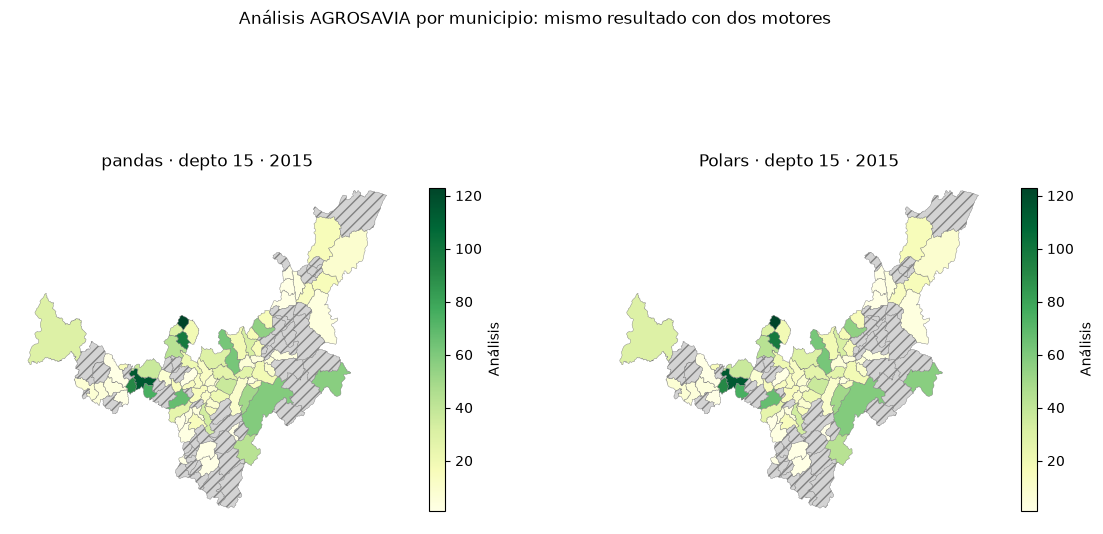

In [9]:
# 5. Resultados tabulares en el mapa (fuera de los tiempos)
print(geometrias.columns.tolist())
poligonos = geometrias[["codigo_municipio", "geometry"]].copy()
poligonos["codigo_municipio"] = poligonos["codigo_municipio"].astype(str).str.strip()
assert poligonos["codigo_municipio"].is_unique

res_pd = consulta_pd(proyeccion_pd)
res_pl = consulta_pl(proyeccion_pl).to_pandas()
comparar(res_pd, pl.from_pandas(res_pl))
for r in (res_pd, res_pl):
    assert r["codigo_municipio"].dropna().is_unique

mapa_pd = poligonos.merge(res_pd.dropna(subset=["codigo_municipio"]).astype({"codigo_municipio": str}),
                          on="codigo_municipio", how="left", validate="one_to_one")
mapa_pl = poligonos.merge(res_pl.dropna(subset=["codigo_municipio"]).astype({"codigo_municipio": str}),
                          on="codigo_municipio", how="left", validate="one_to_one")
sin_geom = res_pd[~res_pd["codigo_municipio"].isin(poligonos["codigo_municipio"])]
print("Resultados sin geometría (incluye grupo sin municipio):", len(sin_geom))
display(sin_geom)
depto_pd = mapa_pd[mapa_pd["codigo_municipio"].str[:2].eq(DEPARTAMENTO)]
depto_pl = mapa_pl[mapa_pl["codigo_municipio"].str[:2].eq(DEPARTAMENTO)]
print("Polígonos del departamento:", len(depto_pd), "| sin resultado:", int(depto_pd["total_analisis"].isna().sum()))
assert np.allclose(depto_pd["total_analisis"].astype(float), depto_pl["total_analisis"].astype(float), equal_nan=True)
assert np.allclose(depto_pd["media_ph"].astype(float), depto_pl["media_ph"].astype(float), atol=1e-6, rtol=0, equal_nan=True)

vmin = float(np.nanmin(depto_pd["total_analisis"].astype(float))) if depto_pd["total_analisis"].notna().any() else 0
vmax = float(np.nanmax(depto_pd["total_analisis"].astype(float))) if depto_pd["total_analisis"].notna().any() else 1
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, datos, motor in [(axes[0], depto_pd, "pandas"), (axes[1], depto_pl, "Polars")]:
    datos.plot(column="total_analisis", ax=ax, cmap="YlGn", vmin=vmin, vmax=vmax, legend=True,
               edgecolor="grey", linewidth=0.3, legend_kwds={"label": "Análisis", "shrink": 0.6},
               missing_kwds={"color": "lightgrey", "hatch": "///", "label": "Sin registros"})
    ax.set_title(f"{motor} · depto {DEPARTAMENTO} · {ANIO}")
    ax.set_axis_off()
fig.suptitle("Análisis AGROSAVIA por municipio: mismo resultado con dos motores")
plt.savefig(OUT + "/comparacion_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

Del GeoPackage solo tomé el código y la geometría, para no mezclar los indicadores de PD04. Uní por separado el resultado de pandas y el de Polars a los mismos polígonos con `validate="one_to_one"`, y antes de mirar los mapas comprobé numéricamente que coinciden conteos y medias. Los dos mapas usan la misma escala de color y el mismo tratamiento de ausentes, así que deben verse iguales; aun así, un mapa igual no reemplaza esa comparación de valores. Las geometrías no entran en ninguna medición de tiempo. Un municipio sin registros no tiene cero análisis: simplemente no hay muestras en la fuente.

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [10]:
# 6. Reejecución, evidencia y decisión
EJECUCION_B = nueva_ejecucion("ejecucion_B")
RUTAS_B = construir_representaciones(EJECUCION_B, proyeccion_pd)
for nombre_inv in ["inventario_anio.csv", "inventario_anio_departamento.csv"]:
    _, a = releer_particiones(EJECUCION, nombre_inv)
    _, b = releer_particiones(EJECUCION_B, nombre_inv)
    pd.testing.assert_frame_equal(a, b)
    print(nombre_inv, "→ contenido A = B:", len(a), "filas")
pd.testing.assert_frame_equal(pd.read_parquet(RUTAS["parquet"]), pd.read_parquet(RUTAS_B["parquet"]))
pd.testing.assert_frame_equal(pd.read_csv(RUTAS["csv"], dtype=TIPOS_PD), pd.read_csv(RUTAS_B["csv"], dtype=TIPOS_PD))

tabla_med = pd.DataFrame(mediciones)
tabla_med[~tabla_med["inicial"]].drop(columns="inicial").to_csv(OUT + "/mediciones.csv", index=False)
tabla_med[tabla_med["inicial"]].drop(columns="inicial").to_csv(OUT + "/mediciones_iniciales.csv", index=False)
medianas = (tabla_med[~tabla_med["inicial"]]
            .groupby(["operacion", "formato", "particionamiento", "motor"])["segundos"]
            .median().rename("mediana_s").reset_index())
medianas.to_csv(OUT + "/medianas.csv", index=False)
resumen_diseños.to_csv(OUT + "/inventario_bytes_archivos.csv", index=False)
pd.DataFrame([
    {"control": "filas_proyeccion", "valor": N},
    {"control": "consulta_pandas_igual_polars", "valor": True},
    {"control": "particiones_releidas_identicas", "valor": True},
    {"control": "ejecucion_A_igual_B", "valor": True},
    {"control": "repeticiones_por_variante", "valor": REPETICIONES},
    {"control": "departamento", "valor": DEPARTAMENTO},
    {"control": "anio", "valor": ANIO},
]).to_csv(OUT + "/controles_equivalencia.csv", index=False)
display(medianas.pivot_table(index=["operacion", "formato", "particionamiento"], columns="motor", values="mediana_s"))
display(resumen_diseños)
print("Mediciones guardadas:", len(tabla_med[~tabla_med["inicial"]]), "repeticiones +",
      int(tabla_med["inicial"].sum()), "ejecuciones iniciales aparte")

inventario_anio.csv → contenido A = B: 92738 filas
inventario_anio_departamento.csv → contenido A = B: 92738 filas


motor                                                pandas    polars
operacion           formato particionamiento                         
consulta_disco      parquet por_anio               0.043395  0.092331
                            por_anio_departamento  0.046558  0.084118
                            unico                  0.040773  0.077005
consulta_disco_lazy parquet unico_scan                  NaN  0.097060
consulta_memoria    memoria ninguno                0.008273  0.007823
escritura           csv     unico                  0.684734  0.168632
                    parquet unico                  0.114750  0.085477
lectura             csv     unico                  0.143326  0.063266
                    parquet unico                  0.047131  0.058486

,diseno,archivos,filas,bytes,mediana_filas_por_archivo,archivos_con_menos_de_100_filas
0,por_anio,12,92738,865014,7442.0,0.0
1,por_anio_departamento,373,92738,2256128,109.0,179.0
2,csv_unico,1,92738,2750014,NaN,NaN
3,parquet_unico,1,92738,830598,NaN,NaN


Mediciones guardadas: 85 repeticiones + 17 ejecuciones iniciales aparte


**Interpretación:**

La segunda construcción, en una carpeta nueva, produce el mismo contenido que la primera aunque los archivos no sean idénticos byte a byte. Las mediciones se guardan en `mediciones.csv` (las cinco repeticiones) y en `mediciones_iniciales.csv` (la primera ejecución, aparte); las medianas usan solo las repeticiones.

**Respuestas** (revisar contra la tabla de medianas):
- **¿Qué mejora con Parquet?** La lectura y el tamaño: Parquet guarda los tipos y está comprimido, así que no hay que interpretar texto ni declarar tipos al leer, como sí pasa con el CSV.
- **¿Cuándo ayuda seleccionar particiones?** Cuando la consulta filtra por la misma clave con la que se dividieron los archivos: se leen menos partes. Si la tabla es pequeña, el costo de abrir varios archivos puede anular esa ventaja.
- **¿Qué diseño genera archivos demasiado pequeños?** El de año + departamento: produce muchas partes con pocas filas, cada una con sus propios metadatos.
- **¿Qué cambia entre memoria y disco?** En memoria solo se mide el cálculo, que es muy rápido. Desde disco domina la lectura de archivos, y las diferencias entre motores se reducen o cambian de orden.
- **¿Qué elegiría?** Para este volumen (menos de 100.000 filas), un **Parquet único** con lectura de solo las columnas necesarias, y de ser posible `scan_parquet` en Polars. Particionar por año solo valdría la pena si el volumen creciera mucho y las consultas siempre filtraran por año.

Las diferencias de milisegundos son pequeñas y variables, así que no las presento como una victoria clara de ningún motor. El tamaño de un DataFrame tampoco equivale a la memoria máxima que usa el proceso.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.